2026-10-23 10:17:08,766:[DEBUG](pygsp.graphs.nngraphs.nngraph.__init__): Using scipy KDTree for k-NN search


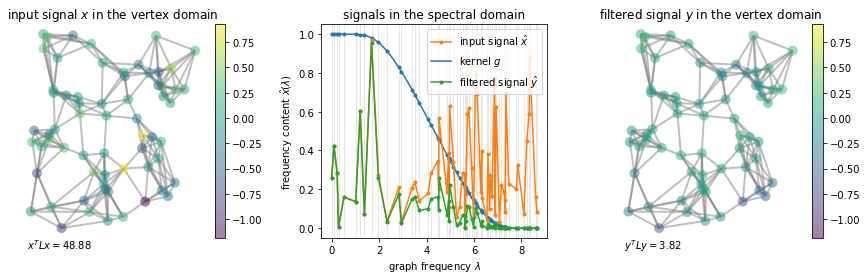

In [15]:
# creds to https://github.com/epfl-lts2/pygsp/blob/master/examples/filtering.py

r"""
Filtering a signal
==================

A graph signal is filtered by transforming it to the spectral domain (via the
Fourier transform), performing a point-wise multiplication (motivated by the
convolution theorem), and transforming it back to the vertex domain (via the
inverse graph Fourier transform).

.. note::

    In practice, filtering is implemented in the vertex domain to avoid the
    computationally expensive graph Fourier transform. To do so, filters are
    implemented as polynomials of the eigenvalues / Laplacian. Hence, filtering
    a signal reduces to its multiplications with sparse matrices (the graph
    Laplacian).

"""

import numpy as np
from matplotlib import pyplot as plt

import pygsp as pg

G = pg.graphs.Sensor(seed=42)
G.compute_fourier_basis()

# g = pg.filters.Rectangular(G, band_max=0.2)
g = pg.filters.Expwin(G, band_max=0.5)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.subplots_adjust(hspace=0.5)

x = np.random.default_rng(1).normal(size=G.N)
# x = np.random.default_rng(42).uniform(-1, 1, size=G.N)
x = 3 * x / np.linalg.norm(x)
y = g.filter(x)
x_hat = G.gft(x).squeeze()
y_hat = G.gft(y).squeeze()

limits = [x.min(), x.max()]

G.plot(x, limits=limits, ax=axes[0], title="input signal $x$ in the vertex domain")
axes[0].text(0, -0.1, f"$x^T L x = {G.dirichlet_energy(x):.2f}$")
axes[0].set_axis_off()

g.plot(ax=axes[1], alpha=1)
line_filt = axes[1].lines[-2]
(line_in,) = axes[1].plot(G.e, np.abs(x_hat), ".-")
(line_out,) = axes[1].plot(G.e, np.abs(y_hat), ".-")
# axes[1].set_xticks(range(0, 16, 4))
axes[1].set_xlabel(r"graph frequency $\lambda$")
axes[1].set_ylabel(r"frequency content $\hat{x}(\lambda)$")
axes[1].set_title(r"signals in the spectral domain")
axes[1].legend([r"input signal $\hat{x}$"])
labels = [
    r"input signal $\hat{x}$",
    "kernel $g$",
    r"filtered signal $\hat{y}$",
]
axes[1].legend([line_in, line_filt, line_out], labels, loc="upper right")

G.plot(y, limits=limits, ax=axes[2], title="filtered signal $y$ in the vertex domain")
axes[2].text(0, -0.1, f"$y^T L y = {G.dirichlet_energy(y):.2f}$")
axes[2].set_axis_off()

fig.tight_layout()

# Literature
- https://arxiv.org/pdf/1611.08751
- https://ieeexplore.ieee.org/stamp/stamp.jsp?tp=&arnumber=7522633
- https://ieeexplore.ieee.org/stamp/stamp.jsp?tp=&arnumber=8307490
- https://pygsp.readthedocs.io/en/stable/

In [17]:
x[0]

0.15101983859593937